### KAE demo: what works

A Koopman autoencoder (KAE) stands in for blocks 7 to 12 of CLIP ViT-B/32. It reads a summary of the state after block 6, takes one linear step `K` in its latent space, and decodes a prediction of the state after block 12. CLIP's own head reads the prediction.

`K` is block diagonal, so the latent splits into 1,024 **modes**. A mode is one complex number `z` per image, and the step is `z₁₂ = λ·z₆` with one eigenvalue `λ` per mode. The size `|λ|` rescales the mode and the angle of `λ` turns it.

What this notebook shows, all on ImageNet validation:
1. **A cheaper stand-in.** The KAE keeps 52% of CLIP's 63% accuracy at a fraction of the compute. This is a pilot of 8 epochs.
2. **A knob that fixes a mistake.** Removing one mode repairs the KAE's errors on snowy photos and leaves other photos alone.
3. **`|λ|` has a meaning.** The larger a mode's `|λ|`, the more the mode follows the class of the image.
4. **The angle of `λ` has a meaning under one training rule.** It repeats across seeds and says how much the later blocks rewrite the mode.

Helpers are in `demo_utils.py`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

from demo_utils import BLUE, CLASS_NAMES, INK, MUTED, ORANGE, SNOW_FOLDERS, Kae
from demo_utils import class_tie, get_hidden, load_clip, load_images, load_snowy, load_val, match_modes, rank_correlation, show_images

torch.set_num_threads(16)
states, labels = load_val()  # [50000 images, 2 (block 6, block 12), 2304]
images = load_images()
kae = Kae("im_iso_2x4k")
z6 = kae.encode(states)  # [50000 images, 1025 modes], complex; 0 where TopK drops the mode

size, angle = kae.eigenvalues.abs(), kae.eigenvalues.angle().rad2deg().abs()
usage = (z6 != 0).float().mean(dim=0)  # share of images that keep each mode
live = usage * len(z6) >= 200  # modes on for at least 200 images
live[0] = False
hidden = get_hidden(kae, states, labels)  # images no gallery shows
print(f"{int(live.sum())} of 1,024 modes are live; each image keeps {int((z6 != 0).sum(dim=1).median())}")

1022 of 1,024 modes are live; each image keeps 128


##### 1. A cheaper stand-in

Accuracy of CLIP's zero-shot classifier on the real block-12 state and on the KAE's prediction of it.

In [2]:
kae_answers, clip_answers = kae.answers(z6), kae.clip_answers(states)
share = lambda hits: f"{hits.float().mean():.1%}"
pd.DataFrame(
    {"ImageNet accuracy": [share(clip_answers == labels), share(kae_answers == labels)], "same answer as CLIP": ["", share(kae_answers == clip_answers)]},
    index=["CLIP", "KAE"],
)

,ImageNet accuracy,same answer as CLIP
CLIP,63.3%,
KAE,52.1%,62.2%


Time for 256 images on this CPU: CLIP's blocks 7 to 12 on the 50 tokens of each image, against the KAE on the summary of those tokens.

In [3]:
blocks = load_clip().visual.transformer.resblocks[6:]
tokens = torch.randn(50, 256, 768)  # [tokens, images, width]


def run_clip():
    x = tokens
    for block in blocks:
        x = block(x)


def run_kae():
    summary = torch.cat([tokens[0], tokens[1:].mean(dim=0), tokens[1:].std(dim=0)], dim=1)
    kae.model.decode(kae.model.koopman_forward(kae.model.encode(summary), 1))


def clock(run):
    began = time.perf_counter()
    run()
    return time.perf_counter() - began


clip_time, kae_time = [min(clock(run) for _ in range(5)) for run in (run_clip, run_kae)]
print(f"CLIP blocks 7-12: {1000 * clip_time:.0f} ms. KAE: {1000 * kae_time:.0f} ms. The KAE is {clip_time / kae_time:.0f} times faster.")

CLIP blocks 7-12: 1547 ms. KAE: 49 ms. The KAE is 32 times faster.


##### 2. A knob that fixes a mistake

The test: 129 snowy photos of 7 vehicle classes, and ImageNet's own 350 validation photos of the same classes. The KAE leans on snow far more than CLIP does, so it calls snowy vehicles snowplows.

The **snow mode** is the mode whose size best separates snowy from normal photos. We pick it on one half of the photos, remove it (`λ` set to 0), and score on the other half.

In [4]:
snow_states, snow_labels, snow_paths = load_snowy()
normal = torch.isin(labels, torch.tensor(list(SNOW_FOLDERS.values())))
test_states, test_labels = torch.cat([states[normal], snow_states]), torch.cat([labels[normal], snow_labels])
is_snowy = torch.arange(len(test_labels)) >= normal.sum()
test_z6 = kae.encode(test_states)


def find_snow_mode(rows):
    candidates = (usage < 0.9).nonzero()[:, 0].tolist()  # modes that are always on are left out
    aucs = [roc_auc_score(is_snowy[rows], test_z6[rows, mode].abs()) for mode in candidates]
    return candidates[int(np.argmax(aucs))]


accuracy = lambda answers, rows: f"{(answers[rows] == test_labels[rows]).float().mean():.1%}"
before, clip_test = kae.answers(test_z6), kae.clip_answers(test_states)
table = []
for half in [0, 1]:
    picked = torch.arange(len(test_labels)) % 2 == half
    mode = find_snow_mode(picked)
    after = kae.answers(test_z6, [mode])
    snowy, other = ~picked & is_snowy, ~picked & ~is_snowy
    table.append(
        {
            "snow mode": mode,
            "snowy: CLIP": accuracy(clip_test, snowy),
            "snowy: KAE": accuracy(before, snowy),
            "snowy: KAE, mode removed": accuracy(after, snowy),
            "normal: KAE": accuracy(before, other),
            "normal: KAE, mode removed": accuracy(after, other),
        }
    )
pd.DataFrame(table, index=["scored on half 1", "scored on half 2"])

,snow mode,snowy: CLIP,snowy: KAE,"snowy: KAE, mode removed",normal: KAE,"normal: KAE, mode removed"
scored on half 1,344,50.0%,29.7%,45.3%,50.9%,50.9%
scored on half 2,344,56.9%,24.6%,47.7%,56.6%,56.6%


The knob is a dial. `λ` of the snow mode is multiplied by a factor from 1 (as trained) down to 0 (removed).

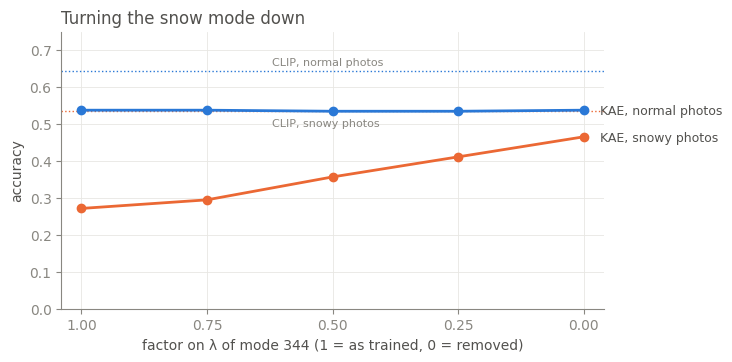

In [5]:
SNOW_MODE = find_snow_mode(slice(None))
factors = [1, 0.75, 0.5, 0.25, 0]
dial = [kae.answers(test_z6, [SNOW_MODE], factor) == test_labels for factor in factors]

fig, ax = plt.subplots(figsize=(7, 3.6))
for rows, color, label, offset in [(is_snowy, ORANGE, "snowy photos", -11), (~is_snowy, BLUE, "normal photos", 4)]:
    clip_level = (clip_test == test_labels)[rows].float().mean()
    ax.plot(factors, [right[rows].float().mean() for right in dial], color=color, lw=2, marker="o", ms=6)
    ax.axhline(clip_level, color=color, lw=1, ls=":")
    ax.annotate(f"KAE, {label}", (0, dial[-1][rows].float().mean()), xytext=(12, -3), textcoords="offset points", color=INK, fontsize=9, annotation_clip=False)
    ax.annotate(f"CLIP, {label}", (0.62, clip_level), xytext=(0, offset), textcoords="offset points", color=MUTED, fontsize=8)
ax.set_xlim(1.04, -0.04)
ax.set_xticks(factors)
ax.set_ylim(0, 0.75)
ax.set_xlabel(f"factor on λ of mode {SNOW_MODE} (1 = as trained, 0 = removed)")
ax.set_ylabel("accuracy")
ax.set_title("Turning the snow mode down")
plt.show()

What the snow mode fires on in ImageNet validation, and snowy photos that removing it fixes (the KAE's answer before → after).

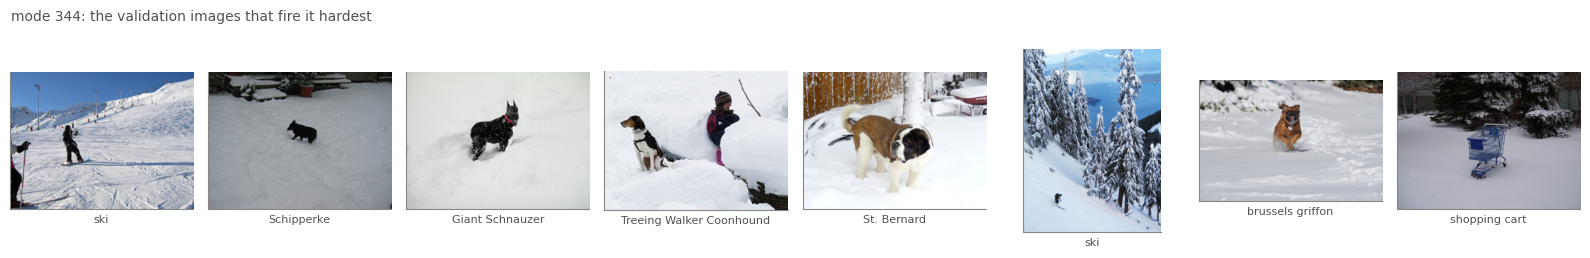

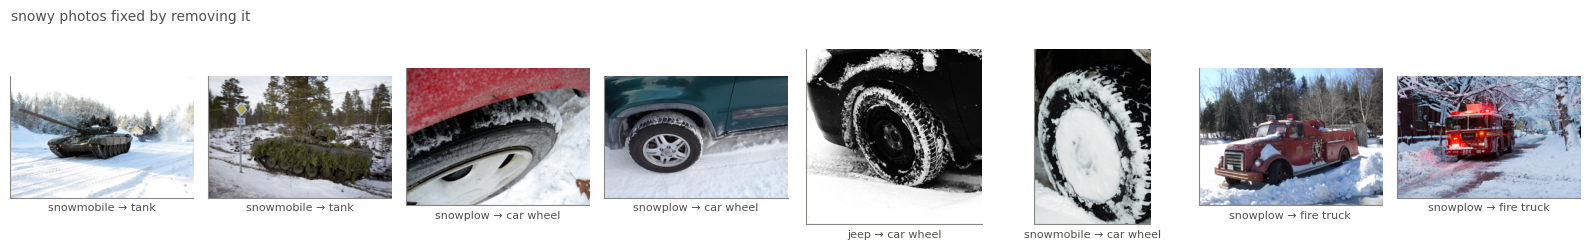

In [6]:
def show_mode(mode, title):
    top = z6[:, mode].abs().argsort(descending=True)
    top = top[~hidden[top]][:8].tolist()
    show_images([images[i]["image"] for i in top], [CLASS_NAMES[labels[i]][:24] for i in top], title)


show_mode(SNOW_MODE, f"mode {SNOW_MODE}: the validation images that fire it hardest")
after = kae.answers(test_z6, [SNOW_MODE])
fixed = (is_snowy & (before != test_labels) & (after == test_labels)).nonzero()[:, 0][:8].tolist()
show_images([snow_paths[i - normal.sum()] for i in fixed], [f"{CLASS_NAMES[before[i]]} → {CLASS_NAMES[after[i]]}"[:30] for i in fixed], "snowy photos fixed by removing it")

The cost: the same edit on all 50,000 validation images.

In [7]:
edited = kae.answers(z6, [SNOW_MODE])
was_right, is_right = kae_answers == labels, edited == labels
print(f"{int((z6[:, SNOW_MODE] != 0).sum()):,} images keep mode {SNOW_MODE}. Removing it fixes {int((is_right & ~was_right).sum())} answers and breaks {int((was_right & ~is_right).sum())}.")
print(f"Accuracy {was_right.float().mean():.2%} → {is_right.float().mean():.2%}")

2,405 images keep mode 344. Removing it fixes 66 answers and breaks 103.
Accuracy 52.11% → 52.04%


##### 3. `|λ|` has a meaning

One dot per live mode. The **class tie** of a mode is the share of its image-to-image variation that the class label explains: near 0 the mode ignores the class, near 1 the class decides it.

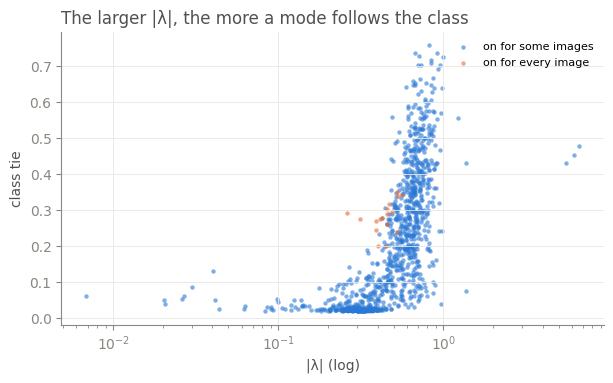

Rank correlation of |λ| with the class tie: +0.79 over 1022 modes (+0.83 with usage held fixed)


In [8]:
tie = class_tie(z6.abs(), labels)
always = usage >= 0.99

fig, ax = plt.subplots(figsize=(7, 3.8))
for rows, color, label in [(live & ~always, BLUE, "on for some images"), (live & always, ORANGE, "on for every image")]:
    ax.scatter(size[rows], tie[rows], s=10, color=color, alpha=0.6, lw=0, label=label)
ax.set_xscale("log")
ax.set_xlabel("|λ| (log)")
ax.set_ylabel("class tie")
ax.set_title("The larger |λ|, the more a mode follows the class")
ax.legend(fontsize=8)
plt.show()
print(f"Rank correlation of |λ| with the class tie: {rank_correlation(size[live], tie[live]):+.2f} over {int(live.sum())} modes ({rank_correlation(size[live], tie[live], (usage[live],)):+.2f} with usage held fixed)")

The three modes with the smallest `|λ|` and the three with the largest, among modes on for under half of the images. The small ones share nothing we can see. The large ones are each a scene or an object.

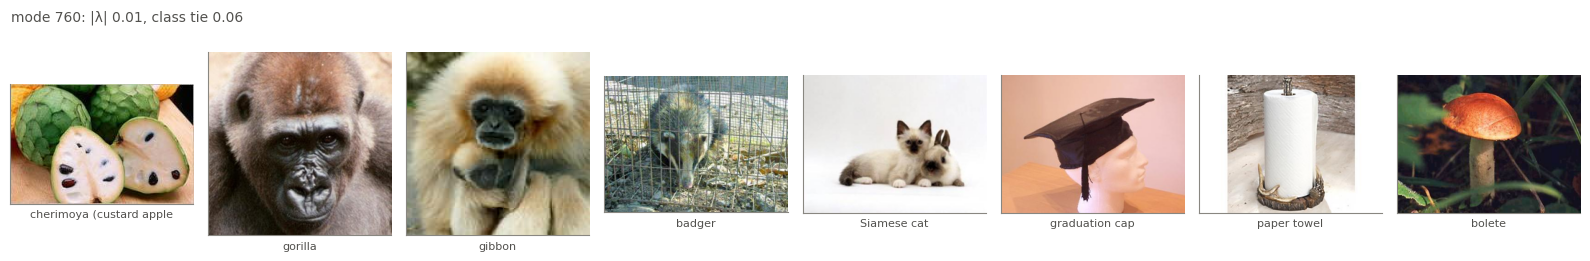

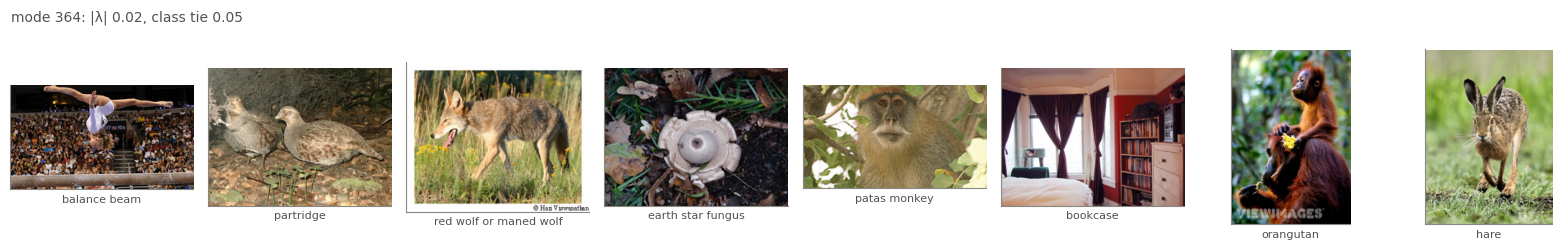

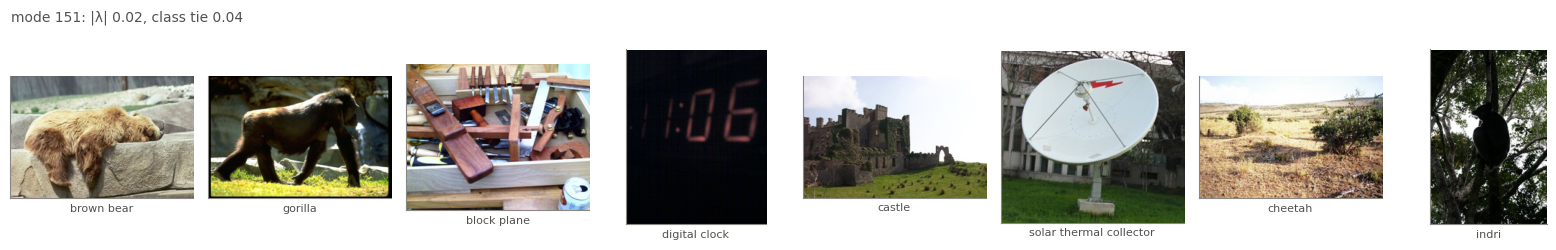

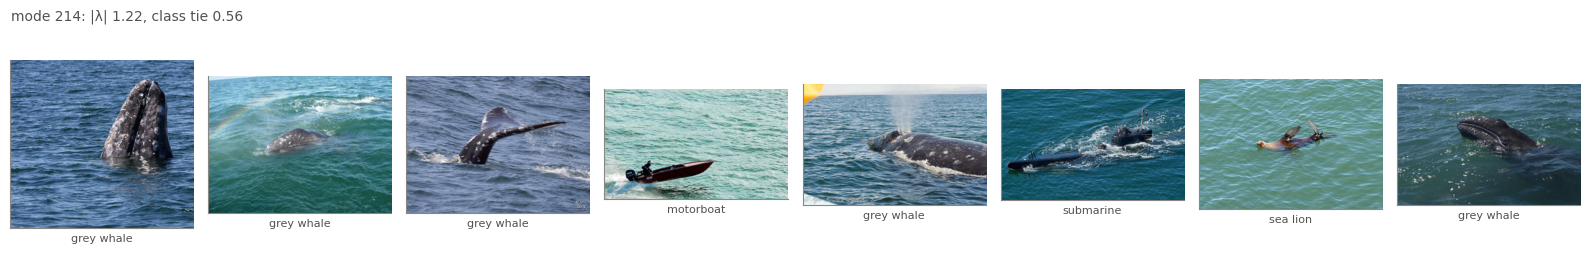

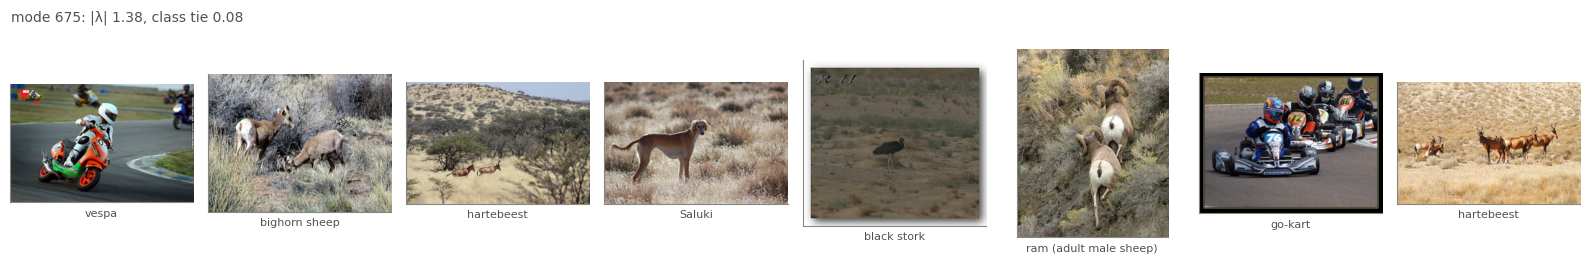

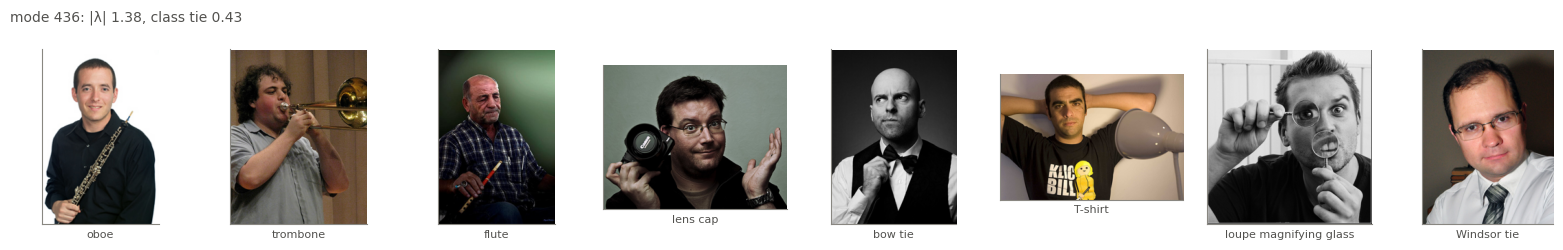

In [9]:
some = live & (usage < 0.5)
by_size = size.argsort()
by_size = by_size[some[by_size]].tolist()
for mode in by_size[:3] + by_size[-3:]:
    show_mode(mode, f"mode {mode}: |λ| {size[mode]:.2f}, class tie {tie[mode]:.2f}")

##### 4. The angle of `λ` has a meaning under one training rule

In the KAE above, the angle does not repeat across seeds. The **real-start rule** changes that: at block 6 a mode is one real number, so its second coordinate at block 12 can only come from the turn of `λ`.

Two KAEs trained with the rule, seeds 0 and 1. Left: modes of the two seeds that fire on the same images, and their angles. Right: for seed 0, how much of a mode's block-6 pattern is still its block-12 pattern in CLIP's real states (**persistence**), against the angle.

NOTE: These two runs used weight decay 0.1, which we have since dropped. The pair without it is queued.

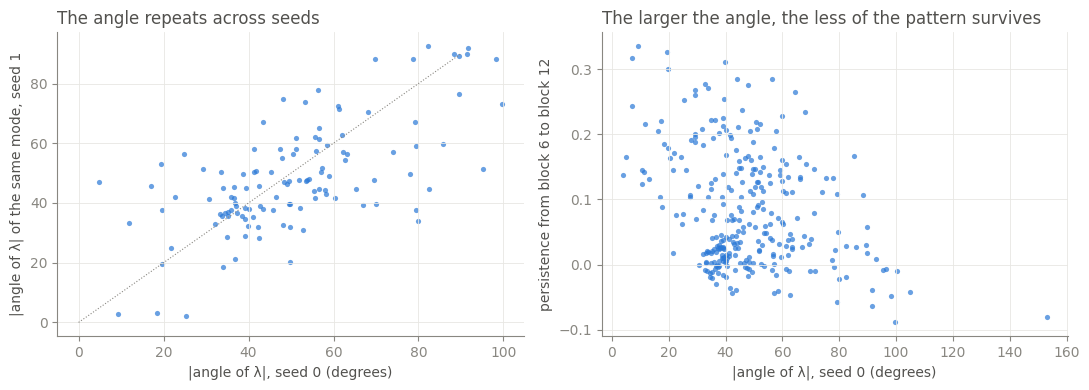

119 matched modes. Rank correlation of the two seeds' angles: +0.61
289 live modes. Rank correlation of angle with persistence: -0.22 (-0.47 with |λ| and usage held fixed)


In [10]:
seed0, seed1 = Kae("im_realstart_2x4k_wd"), Kae("im_realstart_2x4k_wd_s1")
z0, z1 = seed0.encode(states), seed1.encode(states)
get_angle = lambda model: model.eigenvalues.angle().rad2deg().abs()


def get_persistence(model, z):
    """Per live mode: cosine between what the mode adds to CLIP's real block-6 state and to its real block-12 state."""

    modes = ((z != 0).sum(dim=0) >= 200).nonzero()[:, 0]
    x = z.real[:, modes].double()  # under the rule a mode is one real number at block 6
    y = ((states - model.mean) / model.std).double()
    x, y = x - x.mean(dim=0), y - y.mean(dim=0)
    gram = x.T @ x
    gram += 1e-3 * gram.diagonal().mean() * torch.eye(len(modes))
    # shape: [modes, 2 (block 6, block 12), 2304], by ridge regression, so the other modes are held fixed
    added = torch.linalg.solve(gram, x.T @ y.flatten(1)).unflatten(1, (2, -1))
    return modes, torch.cosine_similarity(added[:, 0], added[:, 1], dim=1).float()


twins0, twins1, _ = match_modes(z0, z1)
modes, persistence = get_persistence(seed0, z0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(get_angle(seed0)[twins0], get_angle(seed1)[twins1], s=14, color=BLUE, alpha=0.7, lw=0)
axes[0].plot([0, 90], [0, 90], color=MUTED, lw=0.8, ls=":")
axes[0].set_xlabel("|angle of λ|, seed 0 (degrees)")
axes[0].set_ylabel("|angle of λ| of the same mode, seed 1")
axes[0].set_title("The angle repeats across seeds")
axes[1].scatter(get_angle(seed0)[modes], persistence, s=14, color=BLUE, alpha=0.7, lw=0)
axes[1].set_xlabel("|angle of λ|, seed 0 (degrees)")
axes[1].set_ylabel("persistence from block 6 to block 12")
axes[1].set_title("The larger the angle, the less of the pattern survives")
fig.tight_layout()
plt.show()

fixed = (seed0.eigenvalues.abs()[modes], (z0 != 0).float().mean(dim=0)[modes])
print(f"{len(twins0)} matched modes. Rank correlation of the two seeds' angles: {rank_correlation(get_angle(seed0)[twins0], get_angle(seed1)[twins1]):+.2f}")
print(f"{len(modes)} live modes. Rank correlation of angle with persistence: {rank_correlation(get_angle(seed0)[modes], persistence):+.2f} ({rank_correlation(get_angle(seed0)[modes], persistence, fixed):+.2f} with |λ| and usage held fixed)")

##### What does not work yet

- **Accuracy.** 52% against CLIP's 63%. Width, more epochs and an MLP in place of `K` each added 1 to 2 points.
- **One example.** Snow is the only mistake we have fixed. The KAE makes that mistake more than CLIP does, so the edit repairs the stand-in, not CLIP.
- **Single modes and the angle.** The angle repeats over modes as a whole. The snow mode's own angle did not repeat (80° in one seed, 34° in the other).